<a href="https://colab.research.google.com/github/Dhairya-1103/UCS420CognitiveComputing/blob/main/Assignment8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install nltk textblob wordcloud scikit-learn tensorflow

In [5]:
import re
import nltk
import numpy as np
import matplotlib.pyplot as plt

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from textblob import TextBlob
from wordcloud import WordCloud

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger_eng')

print("All libraries imported successfully!")

All libraries imported successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


In [6]:
paragraph = """
Artificial intelligence is transforming the modern education system.
It helps students learn difficult concepts through personalized learning.
AI-powered tools can generate notes, solve problems, and explain complex topics.
Teachers can use technology to evaluate student performance more efficiently.
However, excessive dependence on artificial intelligence may reduce critical thinking.
Therefore, AI should support human learning rather than replace teachers.
"""
print(paragraph)


Artificial intelligence is transforming the modern education system.
It helps students learn difficult concepts through personalized learning.
AI-powered tools can generate notes, solve problems, and explain complex topics.
Teachers can use technology to evaluate student performance more efficiently.
However, excessive dependence on artificial intelligence may reduce critical thinking.
Therefore, AI should support human learning rather than replace teachers.



In [7]:
clean_text = re.sub(r'[^\w\s]', '', paragraph.lower())

print("Original Text:\n", paragraph)
print("\nCleaned Text:\n", clean_text)

Original Text:
 
Artificial intelligence is transforming the modern education system.
It helps students learn difficult concepts through personalized learning.
AI-powered tools can generate notes, solve problems, and explain complex topics.
Teachers can use technology to evaluate student performance more efficiently.
However, excessive dependence on artificial intelligence may reduce critical thinking.
Therefore, AI should support human learning rather than replace teachers.


Cleaned Text:
 
artificial intelligence is transforming the modern education system
it helps students learn difficult concepts through personalized learning
aipowered tools can generate notes solve problems and explain complex topics
teachers can use technology to evaluate student performance more efficiently
however excessive dependence on artificial intelligence may reduce critical thinking
therefore ai should support human learning rather than replace teachers



In [8]:
words = word_tokenize(clean_text)
sentences = sent_tokenize(paragraph)

print("Word Tokens:")
print(words)

print("\nSentence Tokens:")
for sentence in sentences:
    print(sentence)

print("\nTotal Words:", len(words))
print("Total Sentences:", len(sentences))

Word Tokens:
['artificial', 'intelligence', 'is', 'transforming', 'the', 'modern', 'education', 'system', 'it', 'helps', 'students', 'learn', 'difficult', 'concepts', 'through', 'personalized', 'learning', 'aipowered', 'tools', 'can', 'generate', 'notes', 'solve', 'problems', 'and', 'explain', 'complex', 'topics', 'teachers', 'can', 'use', 'technology', 'to', 'evaluate', 'student', 'performance', 'more', 'efficiently', 'however', 'excessive', 'dependence', 'on', 'artificial', 'intelligence', 'may', 'reduce', 'critical', 'thinking', 'therefore', 'ai', 'should', 'support', 'human', 'learning', 'rather', 'than', 'replace', 'teachers']

Sentence Tokens:

Artificial intelligence is transforming the modern education system.
It helps students learn difficult concepts through personalized learning.
AI-powered tools can generate notes, solve problems, and explain complex topics.
Teachers can use technology to evaluate student performance more efficiently.
However, excessive dependence on artifi

In [9]:
split_tokens = clean_text.split()
nltk_tokens = word_tokenize(clean_text)

print("Python split():")
print(split_tokens)

print("\nNLTK word_tokenize():")
print(nltk_tokens)

print("\nAre both outputs equal?", split_tokens == nltk_tokens)

Python split():
['artificial', 'intelligence', 'is', 'transforming', 'the', 'modern', 'education', 'system', 'it', 'helps', 'students', 'learn', 'difficult', 'concepts', 'through', 'personalized', 'learning', 'aipowered', 'tools', 'can', 'generate', 'notes', 'solve', 'problems', 'and', 'explain', 'complex', 'topics', 'teachers', 'can', 'use', 'technology', 'to', 'evaluate', 'student', 'performance', 'more', 'efficiently', 'however', 'excessive', 'dependence', 'on', 'artificial', 'intelligence', 'may', 'reduce', 'critical', 'thinking', 'therefore', 'ai', 'should', 'support', 'human', 'learning', 'rather', 'than', 'replace', 'teachers']

NLTK word_tokenize():
['artificial', 'intelligence', 'is', 'transforming', 'the', 'modern', 'education', 'system', 'it', 'helps', 'students', 'learn', 'difficult', 'concepts', 'through', 'personalized', 'learning', 'aipowered', 'tools', 'can', 'generate', 'notes', 'solve', 'problems', 'and', 'explain', 'complex', 'topics', 'teachers', 'can', 'use', 'tech

In [10]:
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in nltk_tokens
    if word not in stop_words
]

print("Original Tokens:", nltk_tokens)
print("\nAfter Stopword Removal:", filtered_words)

Original Tokens: ['artificial', 'intelligence', 'is', 'transforming', 'the', 'modern', 'education', 'system', 'it', 'helps', 'students', 'learn', 'difficult', 'concepts', 'through', 'personalized', 'learning', 'aipowered', 'tools', 'can', 'generate', 'notes', 'solve', 'problems', 'and', 'explain', 'complex', 'topics', 'teachers', 'can', 'use', 'technology', 'to', 'evaluate', 'student', 'performance', 'more', 'efficiently', 'however', 'excessive', 'dependence', 'on', 'artificial', 'intelligence', 'may', 'reduce', 'critical', 'thinking', 'therefore', 'ai', 'should', 'support', 'human', 'learning', 'rather', 'than', 'replace', 'teachers']

After Stopword Removal: ['artificial', 'intelligence', 'transforming', 'modern', 'education', 'system', 'helps', 'students', 'learn', 'difficult', 'concepts', 'personalized', 'learning', 'aipowered', 'tools', 'generate', 'notes', 'solve', 'problems', 'explain', 'complex', 'topics', 'teachers', 'use', 'technology', 'evaluate', 'student', 'performance', '

Word Frequency Distribution:
artificial : 2
intelligence : 2
learning : 2
teachers : 2
transforming : 1
modern : 1
education : 1
system : 1
helps : 1
students : 1
learn : 1
difficult : 1
concepts : 1
personalized : 1
aipowered : 1
tools : 1
generate : 1
notes : 1
solve : 1
problems : 1
explain : 1
complex : 1
topics : 1
use : 1
technology : 1
evaluate : 1
student : 1
performance : 1
efficiently : 1
however : 1
excessive : 1
dependence : 1
may : 1
reduce : 1
critical : 1
thinking : 1
therefore : 1
ai : 1
support : 1
human : 1
rather : 1
replace : 1


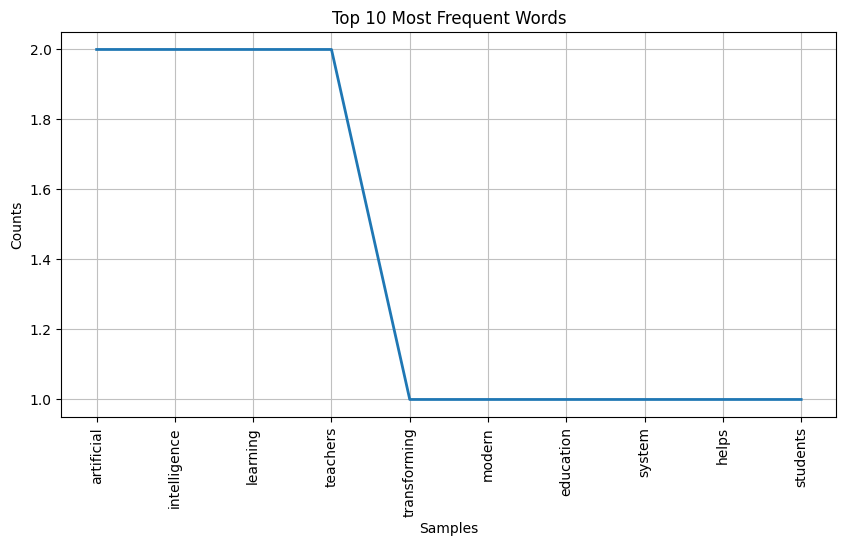

In [11]:
freq_dist = FreqDist(filtered_words)

print("Word Frequency Distribution:")
for word, frequency in freq_dist.most_common():
    print(word, ":", frequency)

plt.figure(figsize=(10, 5))
freq_dist.plot(10, title="Top 10 Most Frequent Words")
plt.show()

In [12]:
extracted_words = re.findall(r'\b[A-Za-z]+\b', paragraph.lower())

print("Extracted Words:")
print(extracted_words)

Extracted Words:
['artificial', 'intelligence', 'is', 'transforming', 'the', 'modern', 'education', 'system', 'it', 'helps', 'students', 'learn', 'difficult', 'concepts', 'through', 'personalized', 'learning', 'ai', 'powered', 'tools', 'can', 'generate', 'notes', 'solve', 'problems', 'and', 'explain', 'complex', 'topics', 'teachers', 'can', 'use', 'technology', 'to', 'evaluate', 'student', 'performance', 'more', 'efficiently', 'however', 'excessive', 'dependence', 'on', 'artificial', 'intelligence', 'may', 'reduce', 'critical', 'thinking', 'therefore', 'ai', 'should', 'support', 'human', 'learning', 'rather', 'than', 'replace', 'teachers']


In [13]:
filtered_words_q2 = [
    word for word in extracted_words
    if word not in stop_words
]

print("Words after stopword removal:")
print(filtered_words_q2)

Words after stopword removal:
['artificial', 'intelligence', 'transforming', 'modern', 'education', 'system', 'helps', 'students', 'learn', 'difficult', 'concepts', 'personalized', 'learning', 'ai', 'powered', 'tools', 'generate', 'notes', 'solve', 'problems', 'explain', 'complex', 'topics', 'teachers', 'use', 'technology', 'evaluate', 'student', 'performance', 'efficiently', 'however', 'excessive', 'dependence', 'artificial', 'intelligence', 'may', 'reduce', 'critical', 'thinking', 'therefore', 'ai', 'support', 'human', 'learning', 'rather', 'replace', 'teachers']


In [14]:
porter = PorterStemmer()

stemmed_words = [
    porter.stem(word)
    for word in filtered_words_q2
]

print("Porter Stemmer Output:")
print(stemmed_words)

Porter Stemmer Output:
['artifici', 'intellig', 'transform', 'modern', 'educ', 'system', 'help', 'student', 'learn', 'difficult', 'concept', 'person', 'learn', 'ai', 'power', 'tool', 'gener', 'note', 'solv', 'problem', 'explain', 'complex', 'topic', 'teacher', 'use', 'technolog', 'evalu', 'student', 'perform', 'effici', 'howev', 'excess', 'depend', 'artifici', 'intellig', 'may', 'reduc', 'critic', 'think', 'therefor', 'ai', 'support', 'human', 'learn', 'rather', 'replac', 'teacher']


In [15]:
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(word):
    tag = nltk.pos_tag([word])[0][1]

    if tag.startswith('J'):
        return 'a'
    elif tag.startswith('V'):
        return 'v'
    elif tag.startswith('R'):
        return 'r'
    else:
        return 'n'

lemmatized_words = [
    lemmatizer.lemmatize(word, get_wordnet_pos(word))
    for word in filtered_words_q2
]

print("WordNet Lemmatizer Output:")
print(lemmatized_words)

WordNet Lemmatizer Output:
['artificial', 'intelligence', 'transform', 'modern', 'education', 'system', 'help', 'student', 'learn', 'difficult', 'concept', 'personalize', 'learn', 'ai', 'power', 'tool', 'generate', 'note', 'solve', 'problem', 'explain', 'complex', 'topic', 'teacher', 'use', 'technology', 'evaluate', 'student', 'performance', 'efficiently', 'however', 'excessive', 'dependence', 'artificial', 'intelligence', 'may', 'reduce', 'critical', 'think', 'therefore', 'ai', 'support', 'human', 'learn', 'rather', 'replace', 'teacher']


In [16]:
comparison = []

for original, stemmed, lemmatized in zip(
    filtered_words_q2,
    stemmed_words,
    lemmatized_words
):
    if stemmed != lemmatized:
        comparison.append(
            (original, stemmed, lemmatized)
        )

print("Words with different outputs:")
print("Original Word | Stemmed | Lemmatized")

for item in comparison:
    print(item)

Words with different outputs:
Original Word | Stemmed | Lemmatized
('artificial', 'artifici', 'artificial')
('intelligence', 'intellig', 'intelligence')
('education', 'educ', 'education')
('personalized', 'person', 'personalize')
('generate', 'gener', 'generate')
('solve', 'solv', 'solve')
('technology', 'technolog', 'technology')
('evaluate', 'evalu', 'evaluate')
('performance', 'perform', 'performance')
('efficiently', 'effici', 'efficiently')
('however', 'howev', 'however')
('excessive', 'excess', 'excessive')
('dependence', 'depend', 'dependence')
('artificial', 'artifici', 'artificial')
('intelligence', 'intellig', 'intelligence')
('reduce', 'reduc', 'reduce')
('critical', 'critic', 'critical')
('therefore', 'therefor', 'therefore')
('replace', 'replac', 'replace')


In [17]:
texts = [
    "Artificial intelligence is transforming modern technology. AI helps automate tasks and improve productivity.",
    "Machine learning allows computers to learn from data. It is widely used in prediction and automation.",
    "Deep learning uses neural networks to solve complex problems. It is important in image recognition and language processing."
]

for i, text in enumerate(texts, 1):
    print(f"Text {i}: {text}\n")

Text 1: Artificial intelligence is transforming modern technology. AI helps automate tasks and improve productivity.

Text 2: Machine learning allows computers to learn from data. It is widely used in prediction and automation.

Text 3: Deep learning uses neural networks to solve complex problems. It is important in image recognition and language processing.



In [18]:
count_vectorizer = CountVectorizer()

bow_matrix = count_vectorizer.fit_transform(texts)

print("Feature Names:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

Feature Names:
['ai' 'allows' 'and' 'artificial' 'automate' 'automation' 'complex'
 'computers' 'data' 'deep' 'from' 'helps' 'image' 'important' 'improve'
 'in' 'intelligence' 'is' 'it' 'language' 'learn' 'learning' 'machine'
 'modern' 'networks' 'neural' 'prediction' 'problems' 'processing'
 'productivity' 'recognition' 'solve' 'tasks' 'technology' 'to'
 'transforming' 'used' 'uses' 'widely']

Bag of Words Matrix:
[[1 0 1 1 1 0 0 0 0 0 0 1 0 0 1 0 1 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 1 0 1
  0 0 0]
 [0 1 1 0 0 1 0 1 1 0 1 0 0 0 0 1 0 1 1 0 1 1 1 0 0 0 1 0 0 0 0 0 0 0 1 0
  1 0 1]
 [0 0 1 0 0 0 1 0 0 1 0 0 1 1 0 1 0 1 1 1 0 1 0 0 1 1 0 1 1 0 1 1 0 0 1 0
  0 1 0]]


In [19]:
tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("TF-IDF Feature Names:")
print(tfidf_vectorizer.get_feature_names_out())

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())

TF-IDF Feature Names:
['ai' 'allows' 'and' 'artificial' 'automate' 'automation' 'complex'
 'computers' 'data' 'deep' 'from' 'helps' 'image' 'important' 'improve'
 'in' 'intelligence' 'is' 'it' 'language' 'learn' 'learning' 'machine'
 'modern' 'networks' 'neural' 'prediction' 'problems' 'processing'
 'productivity' 'recognition' 'solve' 'tasks' 'technology' 'to'
 'transforming' 'used' 'uses' 'widely']

TF-IDF Matrix:
[[0.29238198 0.         0.17268551 0.29238198 0.29238198 0.
  0.         0.         0.         0.         0.         0.29238198
  0.         0.         0.29238198 0.         0.29238198 0.17268551
  0.         0.         0.         0.         0.         0.29238198
  0.         0.         0.         0.         0.         0.29238198
  0.         0.         0.29238198 0.29238198 0.         0.29238198
  0.         0.         0.        ]
 [0.         0.27723014 0.16373659 0.         0.         0.27723014
  0.         0.27723014 0.27723014 0.         0.27723014 0.
  0.         0. 

In [20]:
feature_names = tfidf_vectorizer.get_feature_names_out()
tfidf_array = tfidf_matrix.toarray()

for i, row in enumerate(tfidf_array):
    top_indices = row.argsort()[-3:][::-1]

    print(f"\nTop 3 Keywords in Text {i+1}:")

    for index in top_indices:
        print(
            feature_names[index],
            ":", round(row[index], 4)
        )


Top 3 Keywords in Text 1:
tasks : 0.2924
technology : 0.2924
transforming : 0.2924

Top 3 Keywords in Text 2:
widely : 0.2772
used : 0.2772
computers : 0.2772

Top 3 Keywords in Text 3:
uses : 0.2581
neural : 0.2581
networks : 0.2581


In [21]:
text1 = """
Artificial intelligence enables machines to perform tasks that normally
require human intelligence. It is used in healthcare, education,
automation, robotics, and decision making. AI systems can analyze
large amounts of data and provide intelligent solutions.
"""

text2 = """
Blockchain is a decentralized digital ledger that stores information
securely. It is used in cryptocurrency, banking, supply chain management,
and digital transactions. Blockchain provides transparency,
security, and trust through distributed networks.
"""

print("Text 1:\n", text1)
print("\nText 2:\n", text2)

Text 1:
 
Artificial intelligence enables machines to perform tasks that normally
require human intelligence. It is used in healthcare, education,
automation, robotics, and decision making. AI systems can analyze
large amounts of data and provide intelligent solutions.


Text 2:
 
Blockchain is a decentralized digital ledger that stores information
securely. It is used in cryptocurrency, banking, supply chain management,
and digital transactions. Blockchain provides transparency,
security, and trust through distributed networks.



In [22]:
def preprocess(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    tokens = word_tokenize(text)
    return tokens

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Tokens of Text 1:")
print(tokens1)

print("\nTokens of Text 2:")
print(tokens2)

Tokens of Text 1:
['artificial', 'intelligence', 'enables', 'machines', 'to', 'perform', 'tasks', 'that', 'normally', 'require', 'human', 'intelligence', 'it', 'is', 'used', 'in', 'healthcare', 'education', 'automation', 'robotics', 'and', 'decision', 'making', 'ai', 'systems', 'can', 'analyze', 'large', 'amounts', 'of', 'data', 'and', 'provide', 'intelligent', 'solutions']

Tokens of Text 2:
['blockchain', 'is', 'a', 'decentralized', 'digital', 'ledger', 'that', 'stores', 'information', 'securely', 'it', 'is', 'used', 'in', 'cryptocurrency', 'banking', 'supply', 'chain', 'management', 'and', 'digital', 'transactions', 'blockchain', 'provides', 'transparency', 'security', 'and', 'trust', 'through', 'distributed', 'networks']


In [23]:
set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("Common Words:", intersection)
print("Total Unique Words:", len(union))
print("Jaccard Similarity:", round(jaccard, 4))

Common Words: {'and', 'used', 'that', 'it', 'is', 'in'}
Total Unique Words: 54
Jaccard Similarity: 0.1111


In [24]:
vectorizer = TfidfVectorizer()

tfidf_vectors = vectorizer.fit_transform([text1, text2])

cosine_sim = cosine_similarity(
    tfidf_vectors[0:1],
    tfidf_vectors[1:2]
)

print("Cosine Similarity:", round(cosine_sim[0][0], 4))

Cosine Similarity: 0.1521


In [25]:
print("Jaccard Similarity:", round(jaccard, 4))
print("Cosine Similarity:", round(cosine_sim[0][0], 4))

if cosine_sim[0][0] > jaccard:
    print("Cosine similarity gives a higher similarity score.")
elif cosine_sim[0][0] < jaccard:
    print("Jaccard similarity gives a higher similarity score.")
else:
    print("Both metrics give equal similarity scores.")

Jaccard Similarity: 0.1111
Cosine Similarity: 0.1521
Cosine similarity gives a higher similarity score.


In [26]:
reviews = [
    "The smartphone has an excellent camera and amazing battery life.",
    "I absolutely love this phone. It is fast, smooth and beautiful.",
    "The display quality is fantastic and the performance is impressive.",
    "The battery drains very quickly and the phone becomes extremely slow.",
    "I am disappointed with the poor camera and terrible customer service.",
    "The phone is overpriced and the software has many annoying bugs.",
    "The smartphone is average and works as expected.",
    "It has decent features but nothing particularly special."
]

for i, review in enumerate(reviews, 1):
    print(f"Review {i}: {review}")

Review 1: The smartphone has an excellent camera and amazing battery life.
Review 2: I absolutely love this phone. It is fast, smooth and beautiful.
Review 3: The display quality is fantastic and the performance is impressive.
Review 4: The battery drains very quickly and the phone becomes extremely slow.
Review 5: I am disappointed with the poor camera and terrible customer service.
Review 6: The phone is overpriced and the software has many annoying bugs.
Review 7: The smartphone is average and works as expected.
Review 8: It has decent features but nothing particularly special.


In [27]:
sentiments = []

for review in reviews:
    analysis = TextBlob(review)

    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    sentiments.append({
        "Review": review,
        "Polarity": polarity,
        "Subjectivity": subjectivity
    })

    print("\nReview:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))


Review: The smartphone has an excellent camera and amazing battery life.
Polarity: 0.8
Subjectivity: 0.95

Review: I absolutely love this phone. It is fast, smooth and beautiful.
Polarity: 0.488
Subjectivity: 0.675

Review: The display quality is fantastic and the performance is impressive.
Polarity: 0.7
Subjectivity: 0.95

Review: The battery drains very quickly and the phone becomes extremely slow.
Polarity: 0.067
Subjectivity: 0.525

Review: I am disappointed with the poor camera and terrible customer service.
Polarity: -0.717
Subjectivity: 0.783

Review: The phone is overpriced and the software has many annoying bugs.
Polarity: -0.15
Subjectivity: 0.7

Review: The smartphone is average and works as expected.
Polarity: -0.125
Subjectivity: 0.4

Review: It has decent features but nothing particularly special.
Polarity: 0.262
Subjectivity: 0.619


In [28]:
positive_reviews = []
negative_reviews = []
neutral_reviews = []

for item in sentiments:
    polarity = item["Polarity"]

    if polarity > 0:
        category = "Positive"
        positive_reviews.append(item["Review"])

    elif polarity < 0:
        category = "Negative"
        negative_reviews.append(item["Review"])

    else:
        category = "Neutral"
        neutral_reviews.append(item["Review"])

    print("\nReview:", item["Review"])
    print("Sentiment:", category)

print("\nTotal Positive Reviews:", len(positive_reviews))
print("Total Negative Reviews:", len(negative_reviews))
print("Total Neutral Reviews:", len(neutral_reviews))


Review: The smartphone has an excellent camera and amazing battery life.
Sentiment: Positive

Review: I absolutely love this phone. It is fast, smooth and beautiful.
Sentiment: Positive

Review: The display quality is fantastic and the performance is impressive.
Sentiment: Positive

Review: The battery drains very quickly and the phone becomes extremely slow.
Sentiment: Positive

Review: I am disappointed with the poor camera and terrible customer service.
Sentiment: Negative

Review: The phone is overpriced and the software has many annoying bugs.
Sentiment: Negative

Review: The smartphone is average and works as expected.
Sentiment: Negative

Review: It has decent features but nothing particularly special.
Sentiment: Positive

Total Positive Reviews: 5
Total Negative Reviews: 3
Total Neutral Reviews: 0


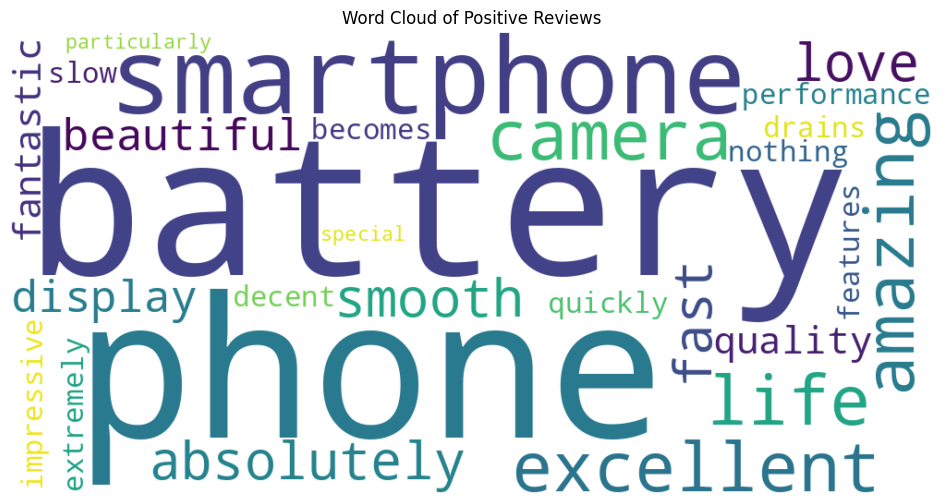

In [29]:
positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=100
).generate(positive_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Positive Reviews")
plt.show()

In [30]:
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_text = """
Technology is changing the way people live and work.
Artificial intelligence helps machines learn from data and make decisions.
Machine learning improves systems through experience and continuous training.
Modern computers can process information quickly and solve complex problems.
The internet connects people across different parts of the world.
Robots are helping humans in industries, hospitals, and laboratories.
Cloud computing allows users to store and access information online.
Technology also improves communication, education, and healthcare services.
However, innovation must be used responsibly to protect privacy and security.
The future of technology depends on creativity, research, and human intelligence.
"""

print(training_text)


Technology is changing the way people live and work.
Artificial intelligence helps machines learn from data and make decisions.
Machine learning improves systems through experience and continuous training.
Modern computers can process information quickly and solve complex problems.
The internet connects people across different parts of the world.
Robots are helping humans in industries, hospitals, and laboratories.
Cloud computing allows users to store and access information online.
Technology also improves communication, education, and healthcare services.
However, innovation must be used responsibly to protect privacy and security.
The future of technology depends on creativity, research, and human intelligence.



In [31]:
tokenizer = Tokenizer()

tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1

print("Word Index:")
print(tokenizer.word_index)

print("\nTotal Unique Words:", total_words)

input_sequences = []

token_list = tokenizer.texts_to_sequences([training_text])[0]

for i in range(1, len(token_list)):
    n_gram_sequence = token_list[:i+1]
    input_sequences.append(n_gram_sequence)

print("\nTotal Input Sequences:", len(input_sequences))

Word Index:
{'and': 1, 'the': 2, 'technology': 3, 'people': 4, 'intelligence': 5, 'improves': 6, 'information': 7, 'of': 8, 'to': 9, 'is': 10, 'changing': 11, 'way': 12, 'live': 13, 'work': 14, 'artificial': 15, 'helps': 16, 'machines': 17, 'learn': 18, 'from': 19, 'data': 20, 'make': 21, 'decisions': 22, 'machine': 23, 'learning': 24, 'systems': 25, 'through': 26, 'experience': 27, 'continuous': 28, 'training': 29, 'modern': 30, 'computers': 31, 'can': 32, 'process': 33, 'quickly': 34, 'solve': 35, 'complex': 36, 'problems': 37, 'internet': 38, 'connects': 39, 'across': 40, 'different': 41, 'parts': 42, 'world': 43, 'robots': 44, 'are': 45, 'helping': 46, 'humans': 47, 'in': 48, 'industries': 49, 'hospitals': 50, 'laboratories': 51, 'cloud': 52, 'computing': 53, 'allows': 54, 'users': 55, 'store': 56, 'access': 57, 'online': 58, 'also': 59, 'communication': 60, 'education': 61, 'healthcare': 62, 'services': 63, 'however': 64, 'innovation': 65, 'must': 66, 'be': 67, 'used': 68, 'respon

In [32]:
max_sequence_len = max(
    len(sequence) for sequence in input_sequences
)

padded_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (96, 96)
Output Shape: (96,)


In [33]:
model = Sequential([
    Embedding(
        total_words,
        64,
        input_length=max_sequence_len - 1
    ),
    LSTM(100),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [34]:
history = model.fit(
    X,
    y,
    epochs=100,
    verbose=1
)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 138ms/step - accuracy: 0.0104 - loss: 4.3699
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 182ms/step - accuracy: 0.0833 - loss: 4.3605
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - accuracy: 0.1042 - loss: 4.3519
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 145ms/step - accuracy: 0.1042 - loss: 4.3399
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.0938 - loss: 4.3130
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.0938 - loss: 4.2674
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 159ms/step - accuracy: 0.0938 - loss: 4.2277
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 190ms/step - accuracy: 0.0938 - loss: 4.1949
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - accuracy: 0.0938 - loss: 4.1542
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.0938 - loss: 4.1148
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 169ms/step - accuracy: 0.0938 - loss: 4.0766
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 134ms/step - accuracy:

In [35]:
def generate_text(seed_text, next_words):
    output_text = seed_text

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences(
            [output_text]
        )[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predicted = model.predict(
            token_list,
            verbose=0
        )

        predicted_word_index = np.argmax(predicted, axis=-1)[0]

        output_word = ""

        for word, index in tokenizer.word_index.items():
            if index == predicted_word_index:
                output_word = word
                break

        if not output_word:
            break

        output_text += " " + output_word

    return output_text

In [36]:
seed_words = ["technology", "artificial", "machine"]

for seed in seed_words:
    generated = generate_text(seed, 10)

    print("\nSeed Word:", seed)
    print("Generated Text:", generated)


Seed Word: technology
Generated Text: technology is is changing the way live and work artificial intelligence

Seed Word: artificial
Generated Text: artificial is changing the way people live and work artificial intelligence

Seed Word: machine
Generated Text: machine is changing the way people live and work artificial intelligence
